# Раздел 1. Основы теории вероятностей
---

## Тема 4. Парадоксы в теории вероятностей
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

### Парадокс Монти Холла
> В телешоу перед игроком три закрытые двери. За одной из них автомобиль, за двумя другими – козы. Игрок выбирает одну дверь, например, первую. Ведущий, который **знает**, где находится автомобиль, открывает одну из двух оставшихся дверей, за которой **коза**, и предлагает игроку изменить выбор. Что выгоднее: остаться при своей двери или перейти к другой закрытой двери?

Интуиция подсказывает: осталось две двери, автомобиль за одной из них, шансы поровну – $\frac{1}{2}$ на $\frac{1}{2}$, смена ничего не даёт. Именно поэтому задача считается **парадоксом**: правильный ответ противоречит здравому смыслу. Покажем, что смена двери **удваивает** шансы на выигрыш, сначала расчётом, затем моделированием.

### Решение по формуле Байеса

Пусть игрок выбрал дверь $1$, а ведущий открыл дверь $3$ (за ней коза).

**Гипотезы.** $H_i$ – автомобиль за дверью $i$. До открытия двери

$P(H_1) = P(H_2) = P(H_3) = \frac{1}{3}$

**Событие** $F$ – ведущий открыл дверь $3$. Условные вероятности – здесь и спрятана вся тонкость, ведь ведущий не может открыть ни дверь с автомобилем, ни дверь игрока:

* $P_{H_1}(F) = \frac{1}{2}$ – автомобиль за выбранной игроком дверью, ведущий открывает любую из двух оставшихся (дверь $2$ или $3$) с равными шансами;
* $P_{H_2}(F) = 1$ – автомобиль за дверью $2$, ведущему **приходится** открыть дверь $3$;
* $P_{H_3}(F) = 0$ – за дверью $3$ автомобиль, открыть её ведущий не вправе.

По **формуле полной вероятности (1.31)**:

$P(F) = \frac{1}{3} \cdot \frac{1}{2} + \frac{1}{3} \cdot 1 + \frac{1}{3} \cdot 0 = \frac{1}{2}$

По **формуле Байеса (1.32)**:

$P_F(H_1) = \frac{\frac{1}{3} \cdot \frac{1}{2}}{\frac{1}{2}} = \frac{1}{3}, \qquad P_F(H_2) = \frac{\frac{1}{3} \cdot 1}{\frac{1}{2}} = \frac{2}{3}$

In [2]:
priors = [Fraction(1, 3)] * 3                       # P(H_i): автомобиль за дверью i
likelihood = [Fraction(1, 2), Fraction(1), Fraction(0)]   # P_Hi(F): ведущий открыл дверь 3

P_F = sum(p * l for p, l in zip(priors, likelihood))   # формула полной вероятности
posterior = [p * l / P_F for p, l in zip(priors, likelihood)]   # формула Байеса

print("P(F) =", P_F)
for i, post in enumerate(posterior, start=1):
    print(f"P(H{i} | F) =", post)

P(F) = 1/2
P(H1 | F) = 1/3
P(H2 | F) = 2/3
P(H3 | F) = 0


Вероятность того, что автомобиль за первоначально выбранной дверью, **не изменилась**: она осталась $\frac{1}{3}$. Всё «освободившееся» место досталось двери $2$ – единственной закрытой двери, которую можно выбрать при смене.

**Короткое объяснение.** Стратегия «остаться» выигрывает тогда и только тогда, когда игрок с первой попытки угадал автомобиль – вероятность $\frac{1}{3}$. Стратегия «перейти» выигрывает во всех остальных случаях, когда игрок выбрал козу ($\frac{2}{3}$): ведущий открывает вторую козу, и оставшаяся закрытая дверь – та самая с автомобилем.

$P(\text{остаться}) = \frac{1}{3}, \qquad P(\text{перейти}) = \frac{2}{3}$

### Моделирование

Смоделируем игру **честно, по шагам**, не используя готовых выводов. Один опыт:

1. автомобиль случайно прячут за одну из трёх дверей;
2. игрок случайно выбирает дверь;
3. ведущий открывает дверь, в которой нет автомобиля и которую не выбрал игрок (если таких дверей две, выбирает любую из них случайно);
4. игрок либо остаётся при своём выборе, либо переходит к единственной другой закрытой двери.

Сыграем $100\,000$ раз при каждой из двух стратегий.

In [3]:
n = 100000
rng = np.random.default_rng()

car = rng.integers(0, 3, n)       # где автомобиль (двери 0, 1, 2)
choice = rng.integers(0, 3, n)    # первоначальный выбор игрока

# две «другие» двери для каждой игры
a = (choice + 1) % 3
b = (choice + 2) % 3

# ведущий открывает дверь с козой; если игрок угадал, у ведущего выбор из двух дверей
coin = rng.random(n) < 0.5
host = np.where(choice == car, np.where(coin, a, b), np.where(a == car, b, a))

switch = 3 - choice - host        # единственная закрытая дверь, кроме выбранной (0 + 1 + 2 = 3)

win_stay = choice == car          # остались и выиграли (массив из T/F, считаем, как 1/0)
win_switch = switch == car        # перешли и выиграли

print("проверка: ведущий ни разу не открыл автомобиль:", bool((host != car).all()))
print("остаться:", win_stay.sum(), "побед из", n)
print("перейти: ", win_switch.sum(), "побед из", n)
round(win_stay.mean(), 4), round(win_switch.mean(), 4)

проверка: ведущий ни разу не открыл автомобиль: True
остаться: 33601 побед из 100000
перейти:  66399 побед из 100000


(np.float64(0.336), np.float64(0.664))

Частоты близки к $\frac{1}{3}$ и $\frac{2}{3}$. С ростом числа игр они всё точнее приближаются к теоретическим вероятностям:

In [4]:
for n_i in [10, 100, 1000, 10000, 100000]:
    print(f"n = {n_i:>6}:  остаться {win_stay[:n_i].mean():.4f},  перейти {win_switch[:n_i].mean():.4f}")

n =     10:  остаться 0.4000,  перейти 0.6000
n =    100:  остаться 0.2900,  перейти 0.7100
n =   1000:  остаться 0.3520,  перейти 0.6480
n =  10000:  остаться 0.3394,  перейти 0.6606
n = 100000:  остаться 0.3360,  перейти 0.6640


### Иллюстрация 1. Сходимость частот

Нарисуем, как по ходу игры меняется доля побед при каждой стратегии. Пунктиром показаны теоретические значения $\frac{1}{3}$ и $\frac{2}{3}$.

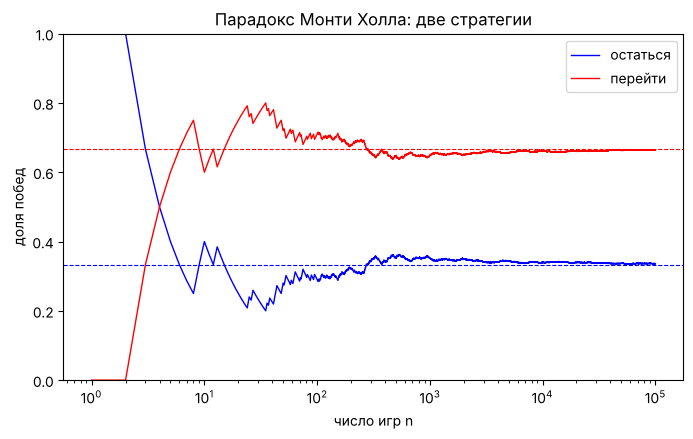

In [5]:
games = np.arange(1, n + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(games, np.cumsum(win_stay) / games, color="blue", lw=1, label="остаться")
plt.plot(games, np.cumsum(win_switch) / games, color="red", lw=1, label="перейти")
plt.axhline(1 / 3, color="blue", ls="--", lw=0.8)
plt.axhline(2 / 3, color="red", ls="--", lw=0.8)
plt.xscale("log")  # логарифмический масштаб: видно и начало, и хвост
plt.ylim(0, 1)
plt.xlabel("число игр n")
plt.ylabel("доля побед")
plt.title("Парадокс Монти Холла: две стратегии")
plt.legend()
plt.show()

Кривые сразу «расходятся» и устойчиво держатся у уровней $\frac{1}{3}$ и $\frac{2}{3}$: смена двери выигрывает вдвое чаще.

### Обобщение: $N$ дверей

Парадокс становится почти очевидным, если дверей много. Пусть их $N$, игрок выбирает одну, а ведущий открывает **$N - 2$ двери с козами**, оставляя закрытыми дверь игрока и ещё одну. Остаться выигрышно только при верной догадке с первого раза: $P = \frac{1}{N}$. При сменe выигрыш во всех остальных случаях: $P = \frac{N - 1}{N}$.

При $N = 100$ игрок с вероятностью $0{,}99$ выбрал козу, и единственная оставшаяся закрытая дверь – та самая, куда ведущий «не решился» заглянуть, – почти наверняка скрывает автомобиль. Проверим для нескольких $N$.

После открытия $N - 2$ коз оставшаяся дверь содержит автомобиль ровно тогда, когда игрок первоначально ошибся, – это и используем в моделировании.

In [6]:
doors = [3, 4, 5, 10, 100]
res_stay, res_switch = [], []

for N in doors:
    car_N = rng.integers(0, N, n)
    choice_N = rng.integers(0, N, n)
    stay_N = (choice_N == car_N).mean()      # остались: выиграли, если сразу угадали
    switch_N = (choice_N != car_N).mean()    # перешли: выиграли, если сначала ошиблись
    res_stay.append(stay_N)
    res_switch.append(switch_N)
    print(f"N = {N:>3}:  остаться {stay_N:.4f} (теория {1 / N:.4f}),  перейти {switch_N:.4f} (теория {(N - 1) / N:.4f})")

N =   3:  остаться 0.3370 (теория 0.3333),  перейти 0.6630 (теория 0.6667)
N =   4:  остаться 0.2518 (теория 0.2500),  перейти 0.7482 (теория 0.7500)
N =   5:  остаться 0.1990 (теория 0.2000),  перейти 0.8010 (теория 0.8000)
N =  10:  остаться 0.1004 (теория 0.1000),  перейти 0.8996 (теория 0.9000)
N = 100:  остаться 0.0100 (теория 0.0100),  перейти 0.9899 (теория 0.9900)


### Иллюстрация 2. Выигрыш при разном числе дверей

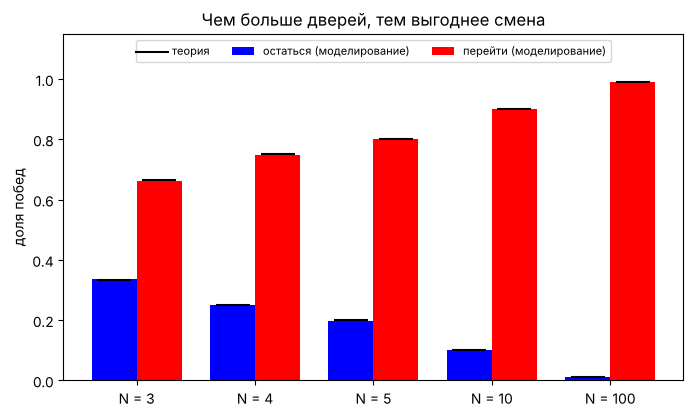

In [7]:
x = np.arange(len(doors))
w = 0.38

plt.figure(figsize=(8, 4.5))
plt.bar(x - w / 2, res_stay, w, color="blue", label="остаться (моделирование)")
plt.bar(x + w / 2, res_switch, w, color="red", label="перейти (моделирование)")
plt.scatter(x - w / 2, [1 / N for N in doors], marker="_", s=600, color="black", zorder=3, label="теория")
plt.scatter(x + w / 2, [(N - 1) / N for N in doors], marker="_", s=600, color="black", zorder=3)
plt.xticks(x, [f"N = {N}" for N in doors])
plt.ylim(0, 1.15)
plt.ylabel("доля побед")
plt.title("Чем больше дверей, тем выгоднее смена")
plt.legend(loc="upper center", ncol=3, fontsize=8)
plt.show()

С ростом $N$ выгода от смены двери растёт: при $N = 3$ это $\frac{2}{3}$ против $\frac{1}{3}$, при $N = 100$ уже $0{,}99$ против $0{,}01$.

### Почему интуиция обманывает: роль знаний ведущего

Ключ к парадоксу – **информация**: ведущий открывает дверь не случайно, а зная, где автомобиль. Его действие несёт сведения о расположении автомобиля. Проверим, что будет, если ведущий **не знает**, где автомобиль, и просто открывает случайную из двух оставшихся дверей. Если ему «повезёт» и за дверью окажется коза, игра продолжается, иначе партия не считается.

По формуле Байеса при $F'$ – «ведущий случайно открыл дверь $3$ и там коза»: $P_{H_1}(F') = \frac{1}{2}$, $P_{H_2}(F') = \frac{1}{2}$, $P_{H_3}(F') = 0$, откуда $P_{F'}(H_1) = P_{F'}(H_2) = \frac{1}{2}$ – теперь смена **ничего не даёт**.

In [8]:
host_rand = np.where(rng.random(n) < 0.5, a, b)   # ведущий открывает случайную из двух оставшихся дверей
valid = host_rand != car                          # оставляем только партии, где за дверью оказалась коза

print("доля партий с козой за дверью ведущего:", round(valid.mean(), 4))
print("остаться:", round(win_stay[valid].mean(), 4))
print("перейти: ", round(((3 - choice - host_rand) == car)[valid].mean(), 4))

доля партий с козой за дверью ведущего: 0.6685
остаться: 0.5026
перейти:  0.4974


Теперь обе стратегии дают около $\frac{1}{2}$ – ровно то, что подсказывала интуиция. Она верна для **неосведомлённого** ведущего, но не для осведомлённого: когда ведущий знает ответ и никогда не открывает автомобиль, его поведение выдаёт информацию, и вероятность смещается в пользу смены двери.

**Вывод.** Парадокс разрешается условными вероятностями: вероятность гипотезы нужно пересчитывать с учётом **того, как именно** получена новая информация. Когда ведущий открывает дверь, не затрагивая выбор игрока, вероятность $\frac{1}{3}$ у его двери не растёт, а оставшаяся неоткрытая дверь получает все $\frac{2}{3}$.

**Ответ:** выгоднее перейти: $P(\text{перейти}) = \frac{2}{3}$, $P(\text{остаться}) = \frac{1}{3}$.